# The Critic Who Cannot Plan
### Karl Popper asked not who should rule but how to limit the damage rulers do. I put a machine (Jev) that cannot write or plan through Dörner's lab of how people fail in complex situations, then made it coach to an AI mayor, to see what an AI critic can do for policy and what only the world can.
**Three parts: why policy needs critics more than planners, whether a machine critic holds up where people fail, and what happens when it reads a policymaker's reasons.**

> **A machine can tell you whether a policy claim could be wrong. Only the world can tell you whether it is.**

Karl Popper thought the oldest question of political philosophy, who should rule, was the wrong one. The question that matters is how to organize institutions so that bad or incompetent rulers can be prevented from doing too much damage. His answer: not better rulers, better criticism. Policies are conjectures: make them in pieces small enough that their effects can be seen, and change course when the world says no.

In 2026, artificial intelligence is offered to policy as the planner's assistant: it forecasts, drafts and simulates. Popper would have asked for the opposite tool, a critic, and one has appeared. **Jev, from TypeSafe, is a model that cannot write a word.** It takes a situation and a typed question and returns a calibrated probability. It cannot propose, cannot plan, cannot explain. It can only say how likely a claim is to meet a criterion, and how sure it is. That is the shape of a critic.

So I put the critic on trial first. In a study published in 1983, Dietrich Dörner put ordinary people in charge of Lohhausen, a small German town inside a computer, and watched them fail in patterns; Harald Schaub, who worked with him, later catalogued the patterns in what reads in places as if Popper had written it. Schaub's six features of complex situations became 44 test cases with known right answers. Then I asked it Popper's own question of 68 written reasons, and gave it the trainer's job over an AI mayor of a small lake town, to see whether refuting a policymaker's reasons changes the policy.

**What a machine critic can do, it turned out, is demarcation: it can tell whether a claim could fail. Refutation needs the world, and a process built so that the world can answer.**

In [1]:
from pathlib import Path
import os
import re
import sys

import matplotlib.pyplot as plt
import numpy as np

ROOT = Path.cwd()
if not (ROOT / "doerner_jev.py").is_file():
    ROOT = ROOT / "doerner"
assert (ROOT / "doerner_jev.py").is_file(), "run the notebook from the folder that holds doerner_jev.py"

# The house palette (quantsoc101's sociodynamics-course/code/sd_style.py), with the same colours inline elsewhere.
sys.path.insert(0, str(ROOT.parent / "sociodynamics-course/code"))
try:
    import sd_style as st
    st.apply()
except ImportError:
    class st:
        BLUE, ORANGE, AQUA = "#2a78d6", "#eb6834", "#1baf7a"
        SURFACE, INK, INK2, MUTED, GRID, BASELINE = "#fcfcfb", "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7"
    plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
                         "grid.color": st.GRID, "figure.facecolor": st.SURFACE, "axes.facecolor": st.SURFACE})

EXPORT_FIGURES = True
FIG_DIR = ROOT / "images" / "doerner"
FIG_DIR.mkdir(parents=True, exist_ok=True)

# Replay only. The keys are blanked before the import and removed after it, so a cache miss raises
# instead of calling a model: every answer below was recorded on 2026-10-09 (Popper's question: 2026-10-12).
os.environ["TYPESAFE_API_KEY"] = os.environ["DEEPSEEK_API_KEY"] = ""
sys.path.insert(0, str(ROOT))
import doerner_jev as d
del os.environ["TYPESAFE_API_KEY"], os.environ["DEEPSEEK_API_KEY"]
d.check()   # the town's delay, side effect and budget rule, and the pure helpers


def p_right(answer, expect):
    """The probability Jev put on the right answer."""
    if answer["type"] == "noul":
        return answer["noul"] if expect else 1 - answer["noul"]
    return answer["probabilities"][expect]


# Experiment 1: the lab, Schaub's six features, 44 cases.
lab = []
for feature, cases in d.FEATURES.items():
    for level, expect, state, q in cases():
        a = d.jev(state, {"q": q})["q"]
        right, conf, _ = d.read(a, expect)
        lab.append({"feature": feature, "level": level, "expect": expect, "right": right, "conf": conf,
                    "p_right": p_right(a, expect), "p_yes": a.get("noul")})


def p_yes(feature, level, expect):
    return next(r["p_yes"] for r in lab if r["feature"] == feature and r["level"] == level and r["expect"] == expect)


# Experiment 2: the remedies.
growth = {}
for level, expect, state, q in d.dynamics():
    xs = list(state["lake"]["algae_cover_percent"].values())
    growth[level] = (expect, [d.jev(s, {"q": q})["q"]["noul"]
                              for s in (state, d.growth_words(xs, 20, False), d.growth_words(xs, 20, True))])
words_25 = d.growth_words([1.0 * 1.25 ** i for i in range(6)], 20, True)["lake"]


def chain_words_v0(state):
    """The first version, kept to show the bug: one effect per cause, so a side branch overwrote the main chain."""
    effects = dict(r[5:-1].split(", ", 1) for r in state["rules"])
    node, seen = d.CHAIN[0], []
    while node in effects and len(seen) < 50:
        node = effects[node]
        seen.append(node)
    return {"plan": state["plan"], "consequences_in_order": seen}


chain = {}
for level, expect, state, q in d.interconnectedness():
    chain[(level, expect)] = [d.jev(s, {"q": q})["q"]["noul"] for s in (state, chain_words_v0(state), d.chain_words(state))]

goals = {}
for level, expect, state, q in d.polytely():
    listed = state["council_goals"]
    ps = {k: a["noul"] for k, a in d.jev(state, d.per_goal(listed)).items()}
    top = sorted(ps, key=ps.get, reverse=True)[:2]
    goals[(level, expect)] = {"one": d.jev(state, {"q": q})["q"]["noul"], "found": all(ps[k] >= 0.5 for k in top),
                              "top": [(listed[int(k[1:])], ps[k]) for k in top]}

# Experiment 3: the catalogue on 34 planted reasons, four question sets.
def catalogue(questions):
    out = []
    for label, reasons in d.PLANTED.items():
        truth = "none" if label.startswith("none") else label
        for reason in reasons:
            out.append((label, truth, reason, d.jev({**d.SITUATION, "steward_reason": reason}, questions)))
    return out


v1, v2 = catalogue({"error": d.ERRORS}), catalogue({"error": d.ERRORS_V2})
c1 = catalogue({"error": d.ERRORS_V2, "checks": d.CHECKS_V1})
c2 = catalogue({"error": d.ERRORS_V2, "checks": d.CHECKS_V2})
picked = lambda rows: [(label, truth, a["error"]["choice"], a["error"]["confidence"]) for label, truth, _, a in rows]
decided = lambda rows: [(label, truth, d.decide(a["error"]["choice"], a["checks"]["noul"]), a["checks"]["noul"]) for label, truth, _, a in rows]


# Experiment 4: the coach. The same loop as doerner_jev.run_coach, replayed.
def coach_run(coached, months=12):
    s, history, note, rows = dict(d.START), [], None, []
    for _ in range(months):
        action, reason = d.mayor(s, history, note if coached else None)
        after = d.step(s, action)
        town = d.words(s)
        a = d.jev({"town": town, "steward_reason": reason}, {"error": d.ERRORS_V2, "checks": d.CHECKS_V2, "side": d.SIDE})
        note = d.coach_note(a)
        rows.append({"month": after["month"], "action": after["action"], "algae_before": s["algae"], "algae": after["algae"],
                     "tourism": after["tourism"], "budget": after["budget"], "reason": reason, "town": town,
                     "error": a["error"]["choice"], "conf": a["error"]["confidence"], "side": a["side"]["noul"],
                     "flags": d.behaviour(s, after, [h.split(":")[0] for h in history]), "note": note})
        history.append(f"{after['action']}: {reason[:80]}")
        s = after
    return rows, s


runs = {coached: coach_run(coached) for coached in (False, True)}
without, with_ = runs[False][0], runs[True][0]

# Month 3 resampled five times each way (replicate_month3.py, cache bypassed for the mayor): parsed from the transcript.
text = (ROOT / "transcripts" / "replicate_month3.txt").read_text()
samples = {}
for block in re.split(r"# month 3, ", text)[1:]:
    label = block.split(chr(10), 1)[0].strip()
    found = re.findall(r"  \d\. (\w+)\s+jev: (\w+) ([\d.]+), side p=([\d.]+)\n     (.+)", block)
    samples[label] = [{"action": a, "error": e, "conf": float(c), "side": float(p), "reason": r} for a, e, c, p, r in found]
off, on = samples["without the note"], samples["with the note"]
month2 = d.step(d.step(dict(d.START), without[0]["action"]), without[1]["action"])   # the state the month-3 prompt saw

# Experiment 5: Popper's question to every reason (recorded 2026-10-12), replayed.
popper = []
for label, reasons in d.PLANTED.items():
    for reason in reasons:
        popper.append((f"planted: {label}", reason, d.jev({**d.SITUATION, "steward_reason": reason}, {"testable": d.TESTABLE})["testable"]))
for coached, name in ((False, "mayor, without the coach"), (True, "mayor, with the coach")):
    for r in runs[coached][0]:
        popper.append((name, r["reason"], d.jev({"town": r["town"], "steward_reason": r["reason"]}, {"testable": d.TESTABLE})["testable"]))
for label, group in (("month 3, without the note", off), ("month 3, with the note", on)):
    for s_ in group:
        popper.append((label, s_["reason"], d.jev({"town": d.words(month2), "steward_reason": s_["reason"]}, {"testable": d.TESTABLE})["testable"]))
GROUPS = list(dict.fromkeys(g for g, _, _ in popper))


def pop_stats(group):
    rows = [(r, a) for g, r, a in popper if g == group]
    return len(rows), round(sum(a["score"] for _, a in rows) / len(rows), 2), sum(d.testable(a) for _, a in rows)


POP = {g: pop_stats(g) for g in GROUPS}

# Every number in the article, once. The asserts pin the prose.
N = {}
N["lab"] = (sum(r["right"] for r in lab), len(lab))
N["conf_right"] = float(np.mean([r["conf"] for r in lab if r["right"]]))
N["conf_wrong"] = float(np.mean([r["conf"] for r in lab if not r["right"]]))
acted = [r for r in lab if r["conf"] >= d.SURE]
N["acted"], N["acted_wrong"], N["deferred"] = len(acted), sum(not r["right"] for r in acted), len(lab) - len(acted)
deferred = [(r["feature"], r["level"], r["expect"]) for r in lab if r["conf"] < d.SURE]
assert N["lab"] == (42, 44) and round(N["conf_right"], 2) == 0.86 and round(N["conf_wrong"], 2) == 0.55, N
assert (N["acted"], N["acted_wrong"], N["deferred"], d.SURE) == (38, 0, 6, 0.7), N
assert sum(f == "dynamics" for f, _, _ in deferred) == 4 and sorted(lv for f, lv, e in deferred if f == "polytely") == ["16 goals", "32 goals"]
assert all(e is False for f, _, e in deferred if f == "polytely"), deferred      # the no-conflict twins

assert [round(p_yes("complexity", "0 distractors", e), 2) for e in (True, False)] == [0.94, 0.12]
assert [round(p_yes("complexity", "1000 distractors", e), 2) for e in (True, False)] == [0.95, 0.09]
assert [round(p_yes("interconnectedness", "11 hops, 16 side rules", e), 2) for e in (True, False)] == [0.72, 0.13]
unsure = [r for r in lab if r["feature"] == "intransparency" and r["expect"] == "cannot_tell"]
assert all(r["right"] for r in unsure) and len(unsure) == 4
assert [round(p_yes("novelty", "invented words", e), 2) for e in (True, False)] == [0.79, 0.17]
g = {r["level"]: round(r["p_yes"], 2) for r in lab if r["feature"] == "dynamics"}
assert g["+25% weekly"] == 0.47 and min(g.values()) == 0.31 and max(g.values()) == 0.77, g
assert sum(r["right"] for r in lab if r["feature"] == "dynamics") == 5
assert [round(p_yes("polytely", f"{n} goals", False), 2) for n in (3, 8, 16, 32)] == [0.21, 0.25, 0.43, 0.57]

assert [round(p, 2) for p in growth["+25% weekly"][1]] == [0.47, 0.71, 0.97]
assert {round(ps[2], 2) for expect, ps in growth.values() if expect} == {0.95, 0.96, 0.97}
assert {round(ps[2], 2) for expect, ps in growth.values() if not expect} == {0.02}
assert "25% per week" in words_25["trend"] and "3.1 weeks" in words_25["trend"] and "week 19" in words_25["projection"], words_25
assert [round(p, 2) for p in chain[("11 hops, 16 side rules", True)]] == [0.72, 0.03, 0.94]
assert round(chain[("6 hops, 12 side rules", True)][1], 2) == 0.07
assert all(goals[(f"{n} goals", True)]["found"] and not goals[(f"{n} goals", False)]["found"] for n in (3, 8, 16, 32))
assert [round(p, 2) for _, p in goals[("32 goals", True)]["top"]] == [0.86, 0.85]

hits = lambda rows: sum(choice == truth for _, truth, choice, _ in rows)
planted = [r for r in picked(v1) if not r[0].startswith("none")]
assert len(planted) == 24 and hits(planted) == 24 and sum(c >= 0.93 for *_, c in planted) == 22
misses = lambda rows: sorted(round(c, 2) for label, truth, choice, c in rows if choice != truth)
assert hits(picked(v1)) == 32 and misses(picked(v1)) == [0.88, 0.95]
assert all(label == "none (near miss)" for label, truth, choice, _ in picked(v1) if choice != truth)
assert hits(decided(c1)) == 29 and hits(decided(c2)) == 33
near = d.PLANTED["none (near miss)"]
v1_pick = {reason: (a["error"]["choice"], a["error"]["confidence"]) for _, _, reason, a in v1}
assert near[5].startswith("The campaign worked last year") and v1_pick[near[5]] == ("methodism", 0.88)
assert near[2].startswith("Algae cover grew 25% a week") and v1_pick[near[2]] == ("momentary_extrapolation", 0.95)
assert near[1].startswith("I expect the algae to fall next month because the new treatment plant comes online in week 8")
assert round(next(a for _, _, reason, a in c2 if reason == near[5])["checks"]["noul"], 2) == 0.8

assert POP == {"planted: central_reduction": (4, 1.08, 1), "planted: wishful_thinking": (4, 1.44, 2),
               "planted: momentary_extrapolation": (4, 1.89, 4), "planted: immunization": (4, 1.07, 0),
               "planted: magical_hypothesis": (4, 1.30, 1), "planted: methodism": (4, 0.88, 0),
               "planted: none": (4, 1.40, 2), "planted: none (near miss)": (6, 1.46, 3),
               "mayor, without the coach": (12, 1.30, 3), "mayor, with the coach": (12, 1.22, 2),
               "month 3, without the note": (5, 1.24, 1), "month 3, with the note": (5, 1.36, 2)}, POP
assert len(popper) == 68 and POP["mayor, without the coach"][2] + POP["mayor, with the coach"][2] == 5
pop_near = {r: a for g, r, a in popper if g == "planted: none (near miss)"}
assert [round(pop_near[near[i]]["score"], 2) for i in (1, 2, 5)] == [1.98, 1.76, 1.96]
assert all(d.testable(pop_near[near[i]]) for i in (1, 2, 5)) and not any(d.testable(pop_near[near[i]]) for i in (0, 3, 4))
assert any("lakes usually clean themselves" in r and d.testable(a) for g, r, a in popper if g == "planted: wishful_thinking")
assert max(a["score"] for g, _, a in popper if g == "planted: momentary_extrapolation") >= 1.76   # as testable as any in the set

assert d.START["growth"] == 0.35 and len(d.ACTIONS) == 4 and len(without) == len(with_) == 12
assert round(without[1]["side"], 2) == 0.21 and without[1]["action"] == "dredge_lake" and with_[1]["note"]
assert "immediately" in without[1]["reason"] and "earlier phosphate cut should keep reducing algae slowly" in with_[2]["reason"]
assert (without[2]["action"], with_[2]["action"]) == ("promote_tourism", "promote_tourism")
assert any(f.startswith("repair service") for f in without[2]["flags"]) and (round(without[2]["algae_before"], 1), round(without[2]["algae"], 1)) == (2.0, 2.8)
assert abs(without[2]["algae"] / without[2]["algae_before"] - 1.45) < 1e-9   # month 3: 35% base growth + the dredge's 10 points
assert round(with_[2]["algae"], 1) == 2.8 and with_[3]["action"] == "dredge_lake"
assert "rising despite early phosphate cuts" in with_[3]["reason"] and (with_[3]["error"], round(with_[3]["conf"], 2)) == ("momentary_extrapolation", 0.57)
assert "will likely keep rising" in with_[9]["reason"] and (round(with_[8]["algae"], 1), round(with_[9]["algae"], 1)) == (4.4, 3.9)   # month 10 forecast, refuted by its own reading
assert "keep rising" not in with_[10]["reason"] and "fell" not in with_[10]["reason"] and "wrong" not in with_[10]["reason"]   # and never remarked on
s3 = d.step(d.step(d.step(dict(d.START), "cut_phosphate"), "wait"), "wait")
assert abs(s3["growth"] - 0.20) < 1e-9   # a month-1 cut lowers growth from month 4 on: month 3's growth did not yet feel it
assert [round(runs[c][1]["algae"], 1) for c in (False, True)] == [2.1, 2.6] and runs[True][1]["tourism"] == runs[False][1]["tourism"] == 100.0

calm = {**d.START, "month": 5, "growth": 0.0, "tourism": 90.0}
assert d.step({**calm, "algae": 15.0}, "wait")["tourism"] == 95.0 and d.step({**calm, "algae": 16.0}, "wait")["tourism"] == 94.0   # harm starts above 15%
scripted = {}
for name, acts in {"wait": ["wait"] * 12, "chase": ["promote_tourism"] * 12, "cut early": ["cut_phosphate", "wait", "cut_phosphate"] + ["wait"] * 9}.items():
    s = dict(d.START)
    for act in acts:
        s = d.step(s, act)
    scripted[name] = s
assert round(scripted["wait"]["algae"], 1) == round(scripted["chase"]["algae"], 1) == 73.3 and (round(scripted["cut early"]["algae"], 1), scripted["cut early"]["tourism"]) == (10.0, 100.0)

assert len(off) == len(on) == 5 and all(s["action"] == "promote_tourism" for s in off + on)
assert (sum(s["side"] >= 0.5 for s in off), sum(s["side"] >= 0.5 for s in on)) == (2, 5)
assert [on[i]["side"] for i in (0, 1, 4)] == [0.69, 0.74, 0.94] and all("earlier phosphate cut" in on[i]["reason"] for i in (0, 1, 4))
for s in off + on:   # the parsed values are the cached answers
    a = d.jev({"town": d.words(month2), "steward_reason": s["reason"]}, {"error": d.ERRORS_V2, "checks": d.CHECKS_V2, "side": d.SIDE})
    assert round(a["side"]["noul"], 2) == s["side"], s

# The figure alt texts quote these too.
dyn_right = sorted(round(r["p_right"], 2) for r in lab if r["feature"] == "dynamics")
assert dyn_right[0] == 0.47 and (dyn_right[1], dyn_right[-1]) == (0.56, 0.77), dyn_right
assert [round(1 - p_yes("polytely", f"{n} goals", False), 2) for n in (3, 8, 16, 32)] == [0.79, 0.75, 0.57, 0.43]
assert round(min(r["p_right"] for r in lab if r["feature"] in ("complexity", "interconnectedness", "intransparency", "novelty")), 2) == 0.72
assert sorted(round(r["conf"], 2) for r in lab if not r["right"]) == [0.53, 0.57]
assert (min(s["side"] for s in on), max(s["side"] for s in on)) == (0.69, 0.99)

# The two full runs: the same actions for four months, apart from month 5, and no note in the prompts in between.
assert [r["action"] for r in without[:4]] == [r["action"] for r in with_[:4]] and without[4]["action"] != with_[4]["action"]
assert with_[1]["note"] and with_[2]["note"] is None and with_[3]["note"] is None

print(f"Ready: lab {N['lab'][0]}/{N['lab'][1]}, catalogue {hits(picked(v1))}/34 then {hits(decided(c2))}/34, "
      f"Popper's question on {len(popper)} reasons, coach replayed for {len(without)} months twice, "
      f"{len(off) + len(on)} month-3 samples checked against the cache.")


def finish(fig, name):
    if EXPORT_FIGURES:
        fig.savefig(FIG_DIR / name, dpi=150, bbox_inches="tight")
    plt.show()

check ok
Ready: lab 42/44, catalogue 32/34 then 33/34, Popper's question on 68 reasons, coach replayed for 12 months twice, 10 month-3 samples checked against the cache.


## 1. The open society needs critics more than planners.

Popper's political writing is an argument about error. We cannot know enough to design a society, and, on my reading, the attempt immunizes itself: when the plan fails, the planner blames the people or the circumstances and keeps the plan. The alternative he called piecemeal social engineering. The piecemeal engineer makes their way step by step, carefully comparing the results expected with the results achieved, always on the look-out for the unavoidable unwanted consequences of any reform, and avoids reforms of a scope that makes it impossible to disentangle causes and effects. Work, he wrote, for the elimination of concrete evils rather than for the realization of abstract goods. And the theoretical social sciences, in his account, exist to trace the unintended consequences of what we intend.

The word for the planner's escape he took from Hans Albert: immunization. A claim rescued after the fact by special circumstances has been immunized against criticism, and Popper saw in that move the line between science and its imitations. **The critical attitude is the opposite: say in advance what would show you wrong, then look.**

Schaub's catalogue of what Dörner's mayors did is the record of thinking without the critical method. One of them, deciding that the old people of the town needed phone booths within reach, worked out the walking time to every booth and placed the new ones with a ruler, while the town's real problems waited. Others fixed whatever complained loudest, gathered only the information that confirmed what they believed, kept models no observation could revise, or explained a failed measure by one-off circumstances and repeated it. Dörner's name for that last one, listed by Schaub, is "immunizing marginal conditioning", Albert's word inside a psychologist's compound. The chapter even quotes Dörner's rule that if you cannot set concrete goals, muddling through is still better than doing nothing: Popper's piecemeal engineer, in a psychologist's mouth.

## 2. A critic that cannot plan.

Jev takes a situation as text and a set of typed questions. Yes-or-no questions come back as probabilities, pick-one questions as a choice with a probability on each option, rubrics as a position on a scale. It does not write replies, produce code or explain its reasoning. Hand it a town record with the line "reservoir: below the minimum for drinking water since Monday", ask whether the drinking water is at risk, and it answers 0.94; with the reservoir normal, 0.12. The vendor's claim is that such numbers are calibrated across many answers, though no single answer is guaranteed; calibrated means that of the things a model puts at 0.9, roughly nine in ten turn out to be so.

**A number can be thresholded, logged, compared and, when low, handed to a person; prose cannot**, and the usual machine judge, another language model, returns a score it asserts with a fluent explanation and no calibrated probability behind it. And a model that cannot write cannot slide from judging the plan into making it. The vendor also publishes "Jev 1.13 jaggedness", a list of the ways this version fails: not a calculator, cannot count reliably, reads dates as text, loses accuracy to indirection and to irrelevant detail in the state; keep the arithmetic in code, it advises, and send the judge only what the question needs. Read that list next to Schaub's six features and the first experiment suggests itself. **Does the critic fail where the planners failed?**

## 3. The critic under test.

Each feature got one fixed question and situations with a known right answer, harder at every level, mostly as yes-and-no twins, so a yes-sayer scores half. **Complexity:** a reservoir hidden among up to 1,000 loud but irrelevant town facts. **Interconnectedness:** a plan to close a weir, and a shuffled rulebook of up to eleven steps from the weir to the school bus that cannot run. **Dynamics:** six weeks of algae readings, and whether algae will cover half the lake by week twenty. **Intransparency:** a paper mill accused on a lab test, or only on a proxy, a cue, its own statement or a rumour. **Many goals:** a council's list of 3 to 32 goals, with or without a hidden contradiction. **Novelty:** the same flood chain in familiar words, invented words, and rules that contradict what everyone knows.

Figure 1 shows how much probability Jev put on the right answer in each case. Four of the six features did not touch it: the reservoir was found among a thousand facts as surely as among none, the school bus eleven steps away, the mill's guilt left open with "cannot tell" when the evidence was a proxy or a rumour, invented words read as written. **On 42 of the 44 cases it was right.** The two that broke it, Schaub would have predicted, with a twist. Given raw weekly numbers, Jev could barely tell a lake that would be half covered from one that would not, and judged a series growing 25% a week wrong, at 0.47: the failure Schaub reports for people. The goal lists broke it the other way round. Dörner's mayors did not notice contradictions between their goals; Jev, asked whether two goals contradict each other when none did, put the probability at 0.21 with three goals and 0.57 with thirty-two. **People miss conflicts; the critic drifted toward inventing them.**

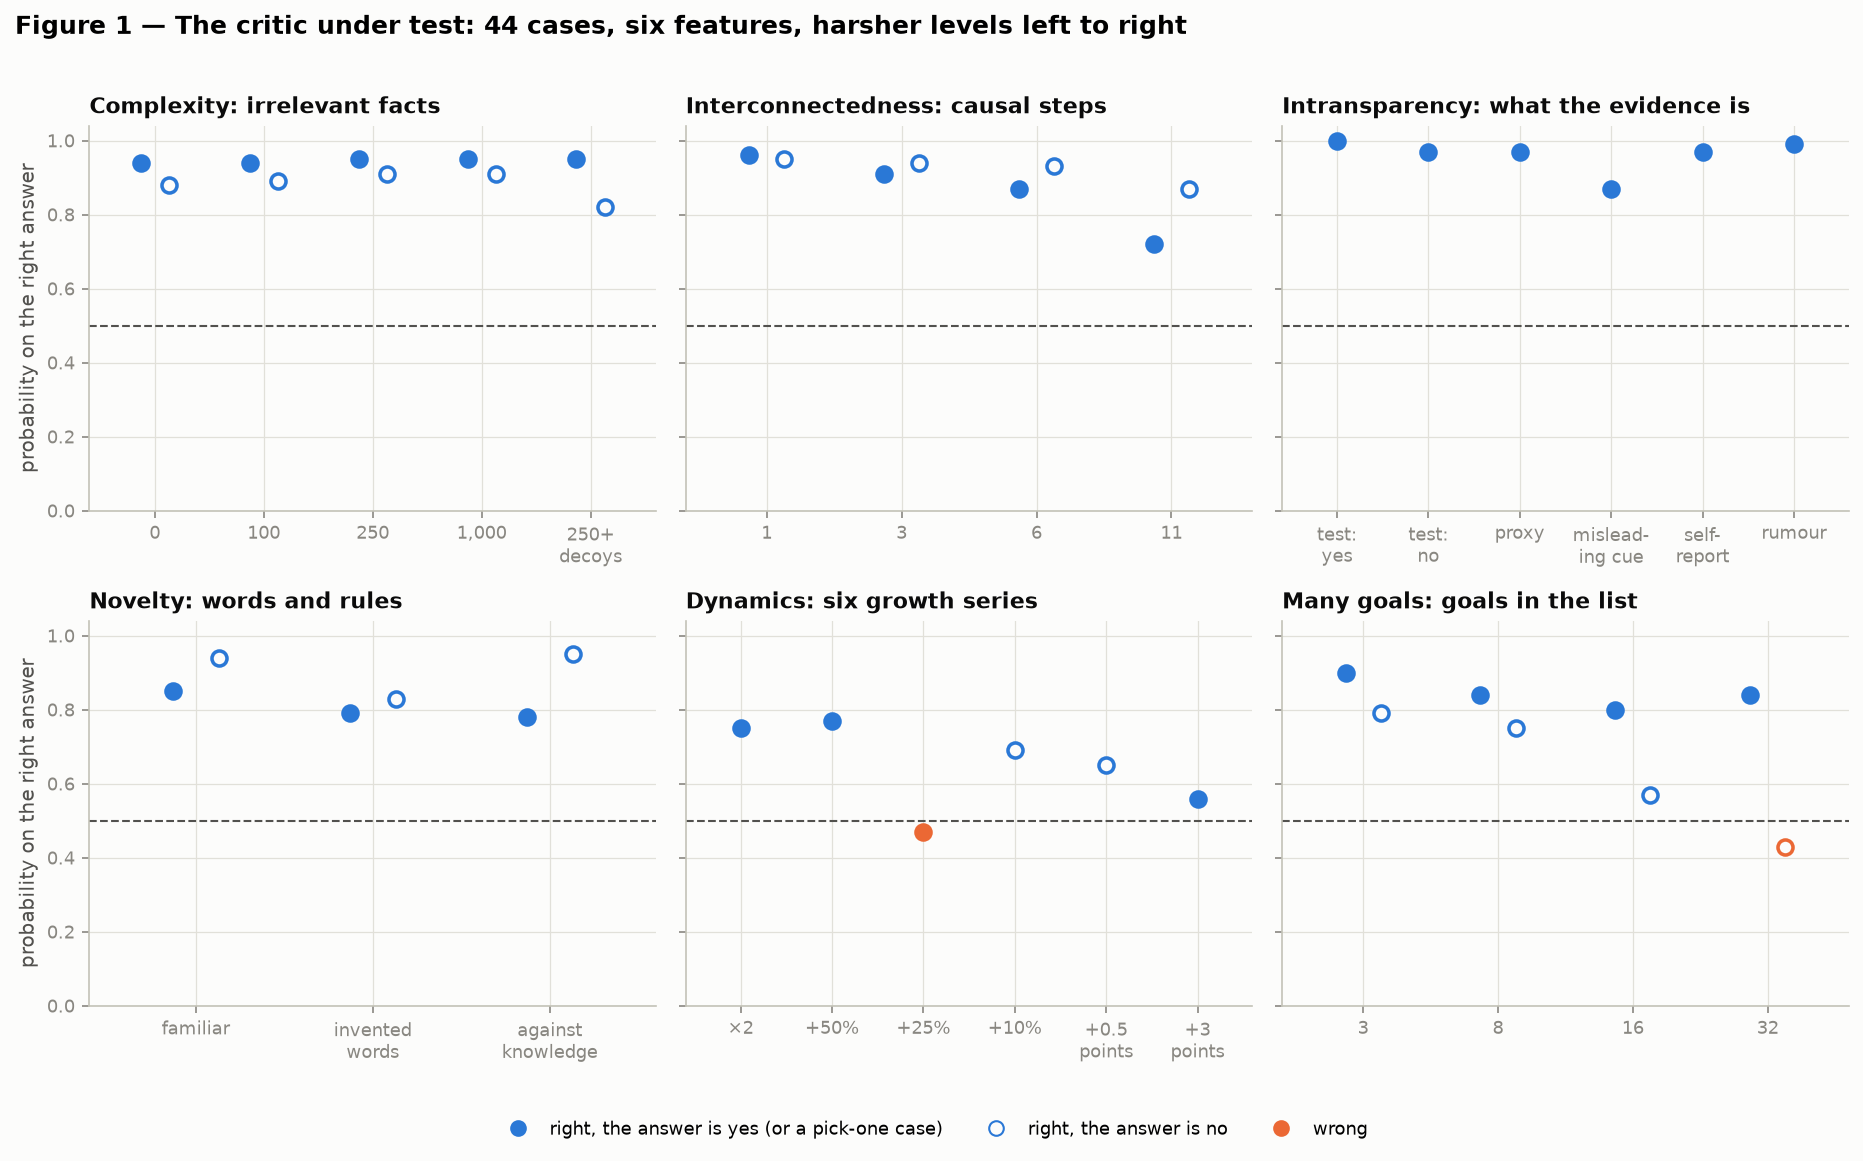

In [2]:
TITLES = {"complexity": "Complexity: irrelevant facts", "interconnectedness": "Interconnectedness: causal steps",
          "intransparency": "Intransparency: what the evidence is", "novelty": "Novelty: words and rules",
          "dynamics": "Dynamics: six growth series", "polytely": "Many goals: goals in the list"}
SHORT = {"0 distractors": "0", "100 distractors": "100", "250 distractors": "250", "1000 distractors": "1,000",
         "250 distractors + water decoys": "250+\ndecoys", "1 hop, 4 side rules": "1", "3 hops, 8 side rules": "3",
         "6 hops, 12 side rules": "6", "11 hops, 16 side rules": "11", "direct test, polluted": "test:\nyes",
         "direct test, clean": "test:\nno", "proxy only": "proxy", "misleading cue": "mislead-\ning cue",
         "self-report only": "self-\nreport", "rumour only": "rumour", "familiar": "familiar",
         "invented words": "invented\nwords", "against world knowledge": "against\nknowledge",
         "doubling weekly": "×2", "+50% weekly": "+50%", "+25% weekly": "+25%", "+10% weekly": "+10%",
         "+0.5 points weekly": "+0.5\npoints", "+3 points weekly": "+3\npoints",
         "3 goals": "3", "8 goals": "8", "16 goals": "16", "32 goals": "32"}

fig, axes = plt.subplots(2, 3, figsize=(12.5, 7.6), sharey=True)
for ax, (feature, title) in zip(axes.flat, TITLES.items()):
    rows = [r for r in lab if r["feature"] == feature]
    levels = list(dict.fromkeys(r["level"] for r in rows))
    paired = {lv for lv in levels if sum(r["level"] == lv for r in rows) == 2}
    for r in rows:
        x = levels.index(r["level"]) + ((-0.13 if r["expect"] is True else 0.13) if r["level"] in paired else 0)
        color = st.BLUE if r["right"] else st.ORANGE
        face = st.SURFACE if r["expect"] is False else color
        ax.scatter(x, r["p_right"], s=52, color=face, edgecolors=color, linewidths=1.7, zorder=3)
    ax.axhline(0.5, color=st.INK2, lw=1, ls="--")
    ax.set_xticks(range(len(levels)), [SHORT[lv] for lv in levels])
    ax.set_xlim(-0.6, len(levels) - 0.4)
    ax.set_title(title, loc="left", fontsize=10.5)
    ax.set_ylim(0, 1.04)
for ax in axes[:, 0]:
    ax.set_ylabel("probability on the right answer")
handles = [plt.Line2D([], [], marker="o", ls="", color=st.BLUE, markersize=7, label="right, the answer is yes (or a pick-one case)"),
           plt.Line2D([], [], marker="o", ls="", markerfacecolor=st.SURFACE, markeredgecolor=st.BLUE, markersize=7, label="right, the answer is no"),
           plt.Line2D([], [], marker="o", ls="", color=st.ORANGE, markersize=7, label="wrong")]
fig.legend(handles=handles, loc="lower center", ncol=3, bbox_to_anchor=(0.5, -0.02))
fig.suptitle("Figure 1 — The critic under test: 44 cases, six features, harsher levels left to right", x=0.01, ha="left", fontweight="bold")
fig.tight_layout(rect=(0, 0.04, 1, 0.97))
finish(fig, "01-lab.png")

## 4. A critic must know when it does not know.

Here the critic parted company with Dörner's mayors, who went wrong with conviction. Jev's confidence, averaged over the 44 cases, was 0.86 when it was right and 0.55 when it was wrong (figure 2). Draw a line at 0.7 and let code act only above it, and **code acts on 38 cases without a single error and hands six to a person**, exactly where it had failed: four growth series and the two longest goal lists without a conflict. This is C. K. Chow's rule of 1970 for a classifier that may abstain; read backwards, a floor at 0.7 says a referral costs about 30% of a wrong answer. It is optimal only when the probabilities are honest, as Hendrickx and colleagues' 2021 survey notes, and section 6 is where they stop being.

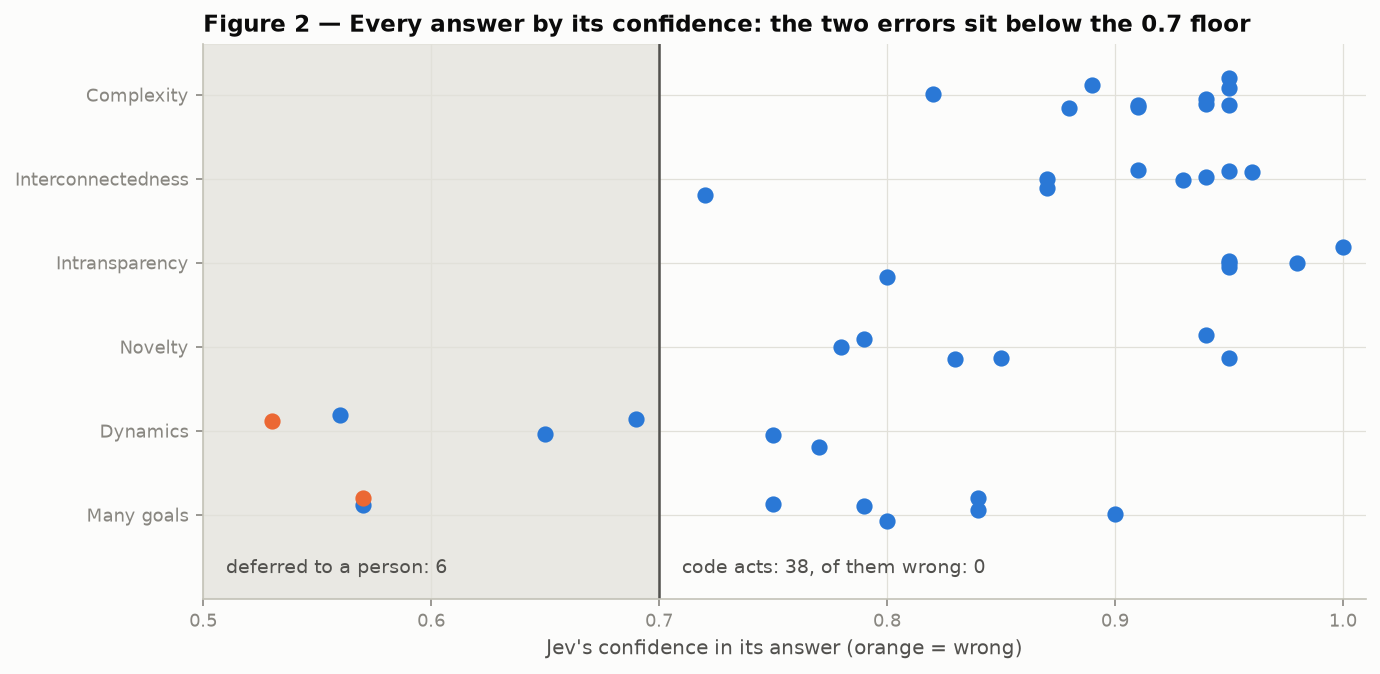

In [3]:
order = list(TITLES)
rng = np.random.default_rng(7)
fig, ax = plt.subplots(figsize=(10, 4.8))
ax.axvspan(0.5, d.SURE, color=st.GRID, alpha=0.7, zorder=0)
ax.axvline(d.SURE, color=st.INK2, lw=1.2)
for r in lab:
    ax.scatter(r["conf"], order.index(r["feature"]) + rng.uniform(-0.2, 0.2), s=46,
               color=st.BLUE if r["right"] else st.ORANGE, zorder=3)
ax.set_yticks(range(len(order)), [TITLES[f].split(":")[0] for f in order])
ax.invert_yaxis()
ax.set_xlim(0.5, 1.01)
ax.set_xlabel("Jev's confidence in its answer (orange = wrong)")
ax.text(0.51, 5.75, f"deferred to a person: {N['deferred']}", fontsize=9, color=st.INK2, va="bottom")
ax.text(d.SURE + 0.01, 5.75, f"code acts: {N['acted']}, of them wrong: {N['acted_wrong']}", fontsize=9, color=st.INK2, va="bottom")
ax.set_ylim(6.0, -0.6)
ax.set_title("Figure 2 — Every answer by its confidence: the two errors sit below the 0.7 floor", loc="left")
finish(fig, "02-confidence.png")

## 5. The critic's evidence must be prepared, and the preparer criticized.

Schaub's remedies for people, forecast, build a model of the system, break the goals into parts, and the vendor's advice to keep the arithmetic in code and send only what the question needs are the same list, and Popper's too: no criticism without a stated claim and prepared evidence. So each remedy became a few lines of code run before Jev reads anything. Given the growth rate in words ("it doubles about every 3.1 weeks"), the critic did better, 0.71 on the series that had failed; given a projection computed by code ("passes 50% in week 19"), it answered between 0.95 and 0.97 on the series that pass and 0.02 on the ones that do not (figure 3). Code that chained the declared rules in causal order moved the eleven-step case from 0.72 to 0.94. **The critic does not need to be taught growth. It needs the growth done.**

My first version of the chaining code kept one effect per cause, so a side branch overwrote the main chain and Jev answered 0.07 and 0.03 on two cases whose right answer was yes. That is central reduction from Schaub's catalogue, a networked system treated as one line of causes, committed by the person who prepares the critic's evidence and caught only because the lab knew the answers. **The critic's input is a conjecture too.**

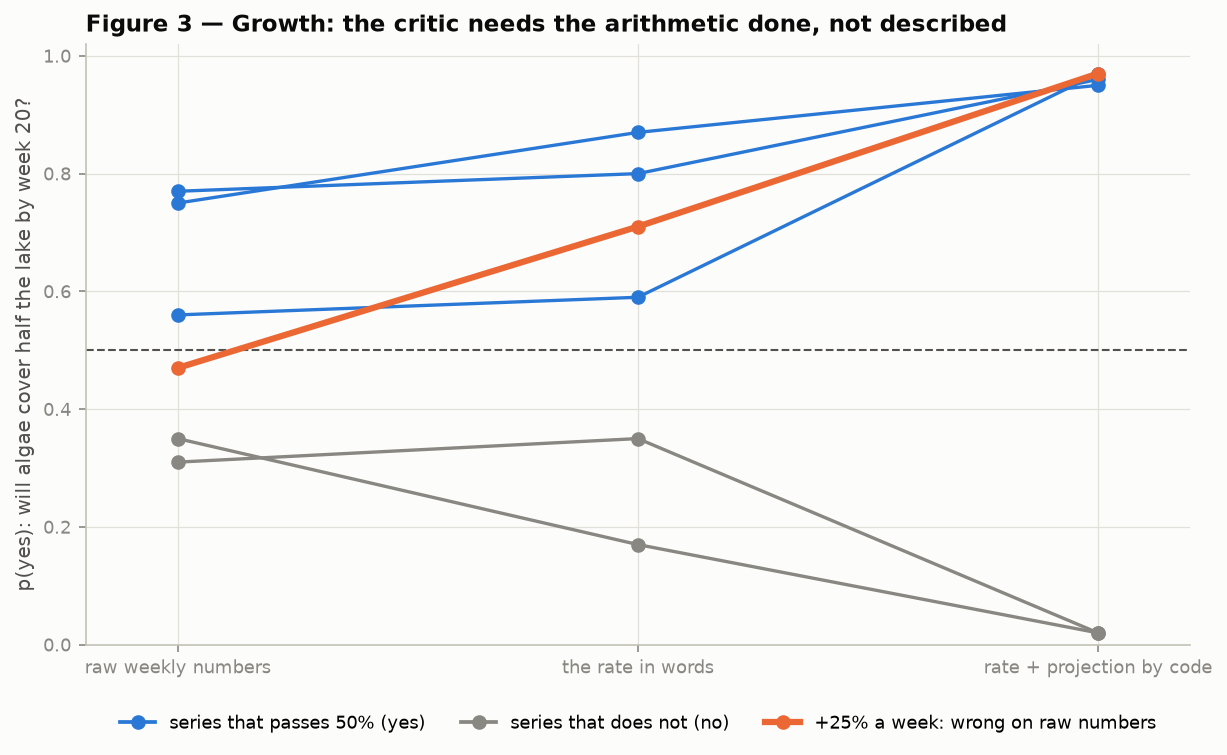

In [4]:
cols = ["raw weekly numbers", "the rate in words", "rate + projection by code"]
fig, ax = plt.subplots(figsize=(9.5, 5.2))
for level, (expect, ps) in growth.items():
    focus = level == "+25% weekly"
    ax.plot(range(3), ps, marker="o", lw=3 if focus else 1.6, zorder=3 if focus else 2,
            color=st.ORANGE if focus else (st.BLUE if expect else st.MUTED))
ax.axhline(0.5, color=st.INK2, lw=1, ls="--")
ax.set_xticks(range(3), cols)
ax.set_xlim(-0.2, 2.2)
ax.set_ylim(0, 1.02)
ax.set_ylabel("p(yes): will algae cover half the lake by week 20?")
ax.legend(handles=[plt.Line2D([], [], color=st.BLUE, marker="o", label="series that passes 50% (yes)"),
                   plt.Line2D([], [], color=st.MUTED, marker="o", label="series that does not (no)"),
                   plt.Line2D([], [], color=st.ORANGE, marker="o", lw=3, label="+25% a week: wrong on raw numbers")],
          loc="upper center", bbox_to_anchor=(0.5, -0.09), ncol=3)
ax.set_title("Figure 3 — Growth: the critic needs the arithmetic done, not described", loc="left")
finish(fig, "03-growth.png")

## 6. Popper's question, asked of every reason.

What can a critic that cannot plan check in a policymaker's reason? Not whether it is true; the world decides that. Whether it is the kind of claim the world could decide. So I asked Jev Popper's question of every reason the experiment had produced: **how could the coming months show this reason to have been wrong?** Scored on three levels: nothing in it could be shown wrong; it expects an outcome but names no measure, place or time to check it; it names what it expects to see, where and by when. Code counted a reason testable when Jev put the top level at even odds or better.

The reasons were the 34 I had planted earlier to test the critic on Schaub's catalogue of errors (four for each of six errors, four clean, six near misses), the 24 an AI mayor gave while governing a lake town for a year, twice, which section 7 describes, and 10 fresh samples of one month of that year.

Figure 4 shows what Popper's question separates and what it does not. Immunization was never testable, 0 of 4, which is its definition. Methodism, repeating what worked before without checking the conditions, 0 of 4. Momentary extrapolation, the current trend drawn straight forward, 4 of 4: a bold conjecture the data could refute, listed by Dörner as an error because it assumes the trend runs straight on; that it is refutable is my reading. Wishful thinking and the clean reasons each split 2 of 4: "it will be fine by summer" is a prediction summer can refute, however badly argued, and a sound reason to wait and look is not yet a prediction. And the near misses, 3 of 6, included sentences as testable as any in the set, among them the compounding sentence, "if that compounding continues it doubles every three weeks, so I'll act now". **Testability is not truth, and it is not soundness. It is the admission ticket to criticism.**

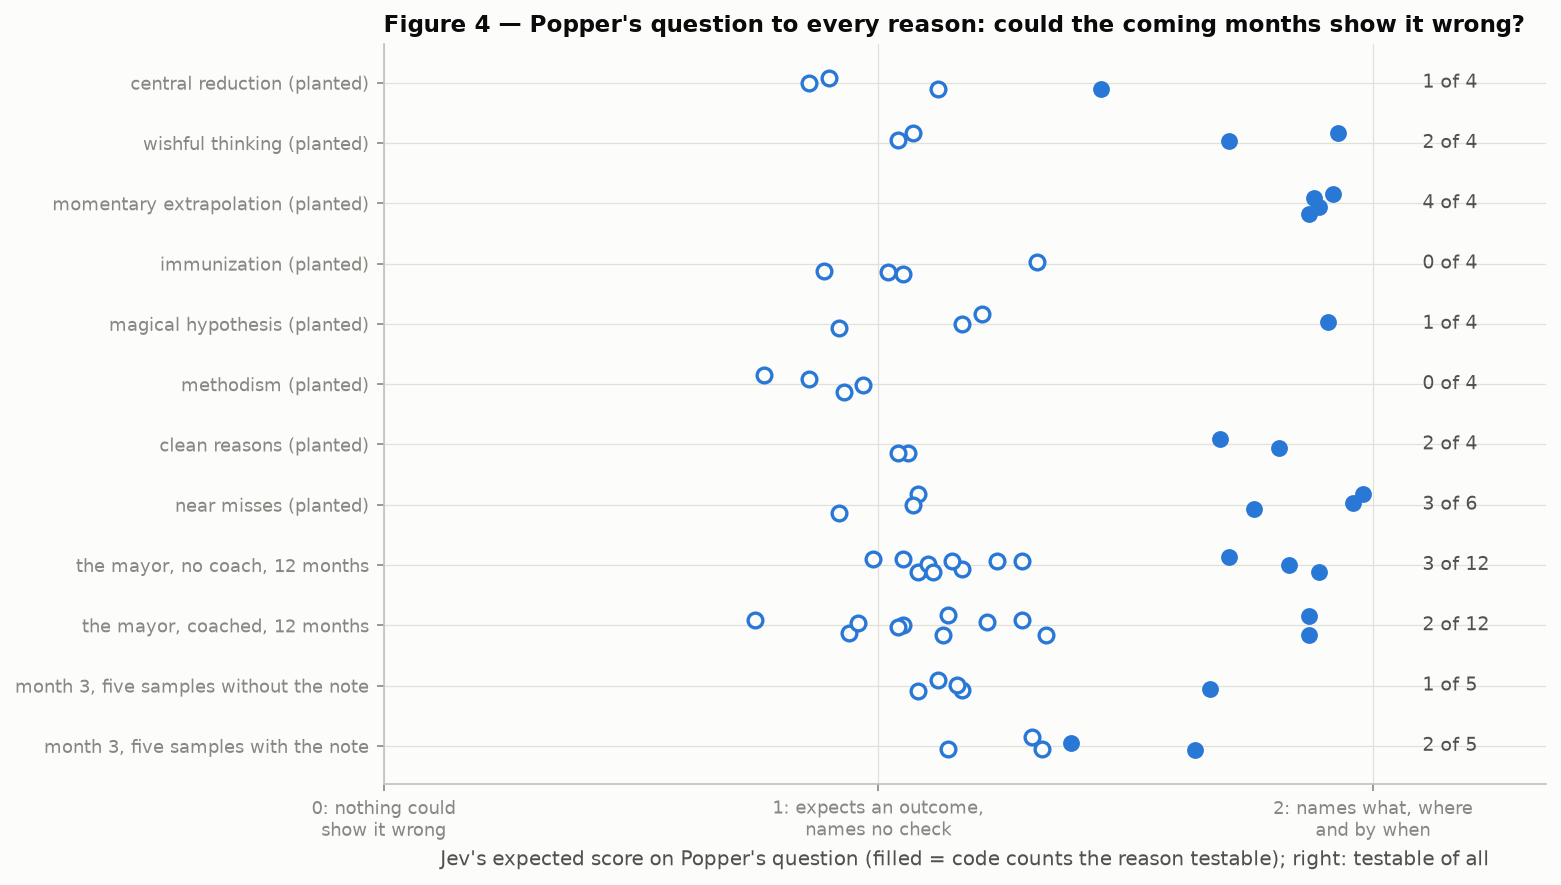

In [5]:
PRETTY = {"planted: central_reduction": "central reduction (planted)", "planted: wishful_thinking": "wishful thinking (planted)",
          "planted: momentary_extrapolation": "momentary extrapolation (planted)", "planted: immunization": "immunization (planted)",
          "planted: magical_hypothesis": "magical hypothesis (planted)", "planted: methodism": "methodism (planted)",
          "planted: none": "clean reasons (planted)", "planted: none (near miss)": "near misses (planted)",
          "mayor, without the coach": "the mayor, no coach, 12 months", "mayor, with the coach": "the mayor, coached, 12 months",
          "month 3, without the note": "month 3, five samples without the note", "month 3, with the note": "month 3, five samples with the note"}
rng = np.random.default_rng(5)
fig, ax = plt.subplots(figsize=(10, 6.4))
for i, grp in enumerate(GROUPS):
    for _, _, a in [x for x in popper if x[0] == grp]:
        y = i + rng.uniform(-0.18, 0.18)
        if d.testable(a):
            ax.scatter(a["score"], y, s=50, color=st.BLUE, zorder=3)
        else:
            ax.scatter(a["score"], y, s=50, facecolors=st.SURFACE, edgecolors=st.BLUE, linewidths=1.6, zorder=3)
    n, mean, k = POP[grp]
    ax.text(2.1, i, f"{k} of {n}", va="center", fontsize=9, color=st.INK2)
ax.set_yticks(range(len(GROUPS)), [PRETTY[g] for g in GROUPS])
ax.invert_yaxis()
ax.set_xlim(0, 2.35)
ax.set_xticks([0, 1, 2], ["0: nothing could\nshow it wrong", "1: expects an outcome,\nnames no check", "2: names what, where\nand by when"])
ax.set_xlabel("Jev's expected score on Popper's question (filled = code counts the reason testable); right: testable of all")
ax.set_title("Figure 4 — Popper's question to every reason: could the coming months show it wrong?", loc="left")
finish(fig, "07-popper.png")

That is where Dörner's psychology and Popper's logic part, and the critic sided with the psychology. The two sentences the critic had earlier flagged as errors, wrongly, are among the three near misses Popper's question passed (figure 5): the beach reason as methodism at 0.88, although it checks exactly the condition that defines methodism, and the compounding sentence as momentary extrapolation at 0.95. The critic had caught all twenty-four planted errors, most at 0.93 or higher, and was fooled by sentences that wear the surface of an error while doing what Popper asks for. **No confidence floor catches a mistake at 0.95.** A second, literal yes-or-no question about whether the reason checks a present fact, combined in code, left one miss in thirty-four, written after seeing the misses.

The mayor answered Popper's question more bleakly: **5 of its 24 reasons named what would show them wrong**, 3 of 12 without a coach and 2 of 12 with one. The coach's note, which only ever spoke about side effects, barely moved it in the month sampled five times each way: 1 of 5 reasons testable without the note, 2 of 5 with it. An AI policymaker, left to itself, mostly does not say what would prove it wrong; a coach that criticizes reasons did not teach it to.

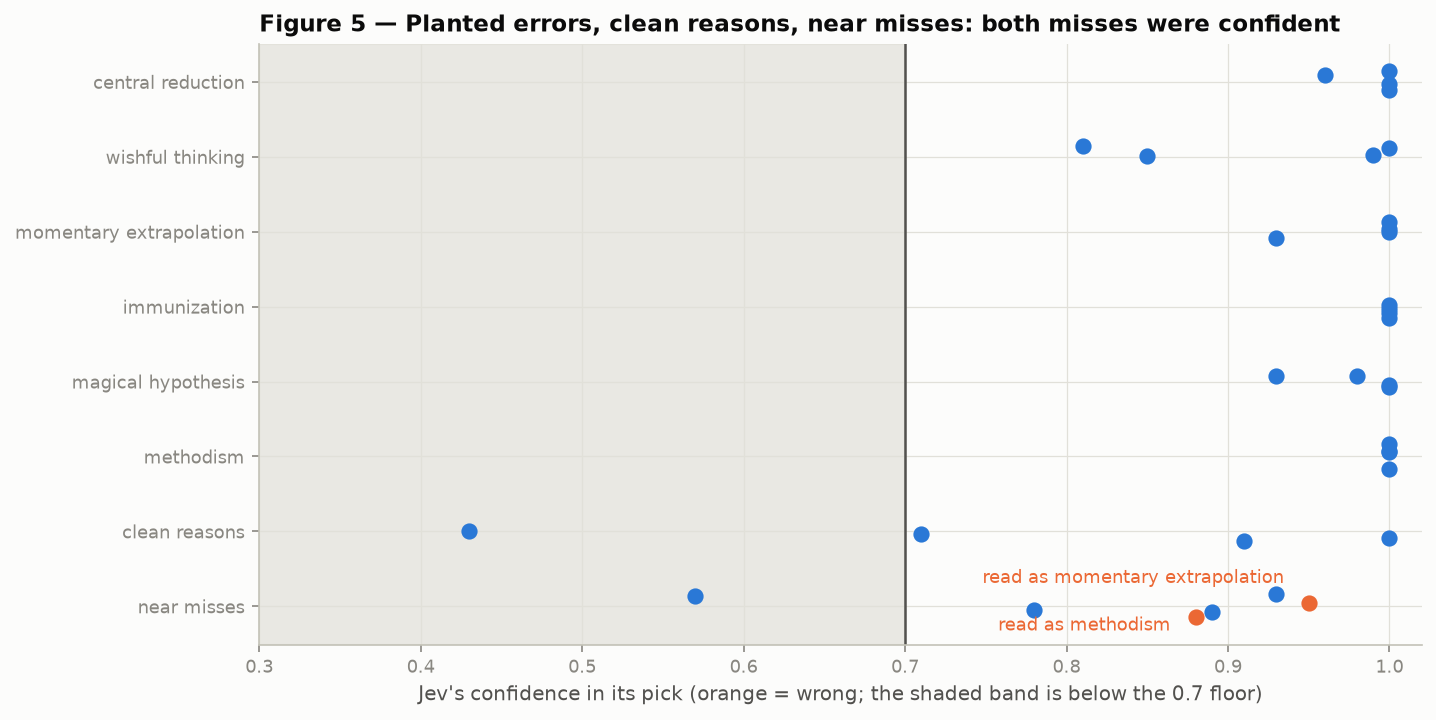

In [6]:
groups = list(d.PLANTED)
names = {"central_reduction": "central reduction", "wishful_thinking": "wishful thinking",
         "momentary_extrapolation": "momentary extrapolation", "immunization": "immunization",
         "magical_hypothesis": "magical hypothesis", "methodism": "methodism", "none": "clean reasons",
         "none (near miss)": "near misses"}
rng = np.random.default_rng(3)
fig, ax = plt.subplots(figsize=(10, 5.2))
ax.axvspan(0.3, d.SURE, color=st.GRID, alpha=0.7, zorder=0)
ax.axvline(d.SURE, color=st.INK2, lw=1.2)
for label, truth, choice, conf in picked(v1):
    y = groups.index(label) + rng.uniform(-0.17, 0.17)
    ok = choice == truth
    ax.scatter(conf, y, s=46, color=st.BLUE if ok else st.ORANGE, zorder=3)
    if not ok:
        ax.annotate(f"read as {names[choice]}", (conf, y), xytext=(-12, 12 if choice == "momentary_extrapolation" else -4),
                    textcoords="offset points", fontsize=8.5, color=st.ORANGE, ha="right", va="center")
ax.set_yticks(range(len(groups)), [names[g] for g in groups])
ax.invert_yaxis()
ax.set_xlim(0.3, 1.02)
ax.set_xlabel("Jev's confidence in its pick (orange = wrong; the shaded band is below the 0.7 floor)")
ax.set_title("Figure 5 — Planted errors, clean reasons, near misses: both misses were confident", loc="left")
finish(fig, "05-catalogue.png")

## 7. Refuting a reason is not refuting a policy.

**Then Jev got the trainer's job.** The town is a Lohhausen of my own, declared in a few dozen lines of code: algae the quiet critical variable, compounding at 35% a month, harming tourism above 15% of the lake, responding to a cut in farm phosphate only from the third month after the order; tourism the loud one, dipping every off-season, recovering by itself, making the headline whenever it is low; dredging halving the algae at once but making it grow faster for two months. Waiting or chasing headlines ends with algae over 73% of the lake; two early cuts end at 10%. The mayor was DeepSeek's flash model, choosing one action a month with a sentence of reason. Jev read every reason, with the town in words rather than numbers, and answered three questions: which catalogue error, if any; does it check the conditions; does it mention a delayed effect or a side effect of the chosen action. The coach spoke on a confident error or a reason blind to side effects, and only ever named the error, never what to do. The year ran twice, with the notes passed on and with the coach silent.

In month 2 the mayor dredged, with a reason that spoke of immediate results and said nothing about delayed or side effects; Jev put that at 0.21, and the coach said so. It was the year's most useful note: that side effect is ten of the 45 points by which the algae grow in month 3. In month 3 the mayor promoted tourism in both runs; the coached reason now mentioned the slow phosphate effect. One month is one sample, so I asked month 3 again, five times with the note and five without (figure 6). Without the note, two of five reasons named a delayed or side effect; with it, five of five. **The action did not move. Promote tourism, ten times out of ten.**

Popper has a name for what the coached mayor did: its reasons improved and its deed stayed, the claim repaired until the criticism no longer touched it, the immunizing move performed by a language model prompted to reflect. **What this is not is Goodhart's law.** The mayor was not gaming anyone; the note only ever talked about words. What did not happen is the step a critic exists for, from seeing the flaw in a reason to reconsidering the decision.

And then the world did what the critic could not. The coached mayor's month-3 reason forecast that "the earlier phosphate cut should keep reducing algae slowly". Month 4 refuted it: the algae stood at 2.8% of the lake, up from 2.0, the cut not yet acting, and the mayor said so in its next reason, "rising despite early phosphate cuts", and dredged. That was the one refutation the mayor acknowledged, and **the critic never saw it**: reading one reason at a time, it scored the month-4 reason as momentary extrapolation at 0.57 and moved on. A second forecast, in month 10, that the algae "will likely keep rising", was refuted by the next reading, 4.4% to 3.9%, and no one remarked on it. A critic that reads sentences cannot compare results expected with results achieved; only code holding last month's claim against this month's lake can, and nothing in the loop did.

Two cautions. Three of the five coached reasons named only the earlier cut's delay, not the campaign's, and Jev, asked about the chosen action, scored them 0.69 to 0.94 anyway. And whether the action should have changed, nothing here can say: my code labelled it repair-service behaviour, but the growth was from 2.0% to 2.8% of the lake, far below the harm line, and both years ended with a clean lake, at 2.1% and 2.6%. **The label is a definition, not a verdict**, and a deed could be labelled at all only because the town was declared with its critical variable named. The two runs drifted apart from month 5 on; with one run each way that cannot be told from noise.

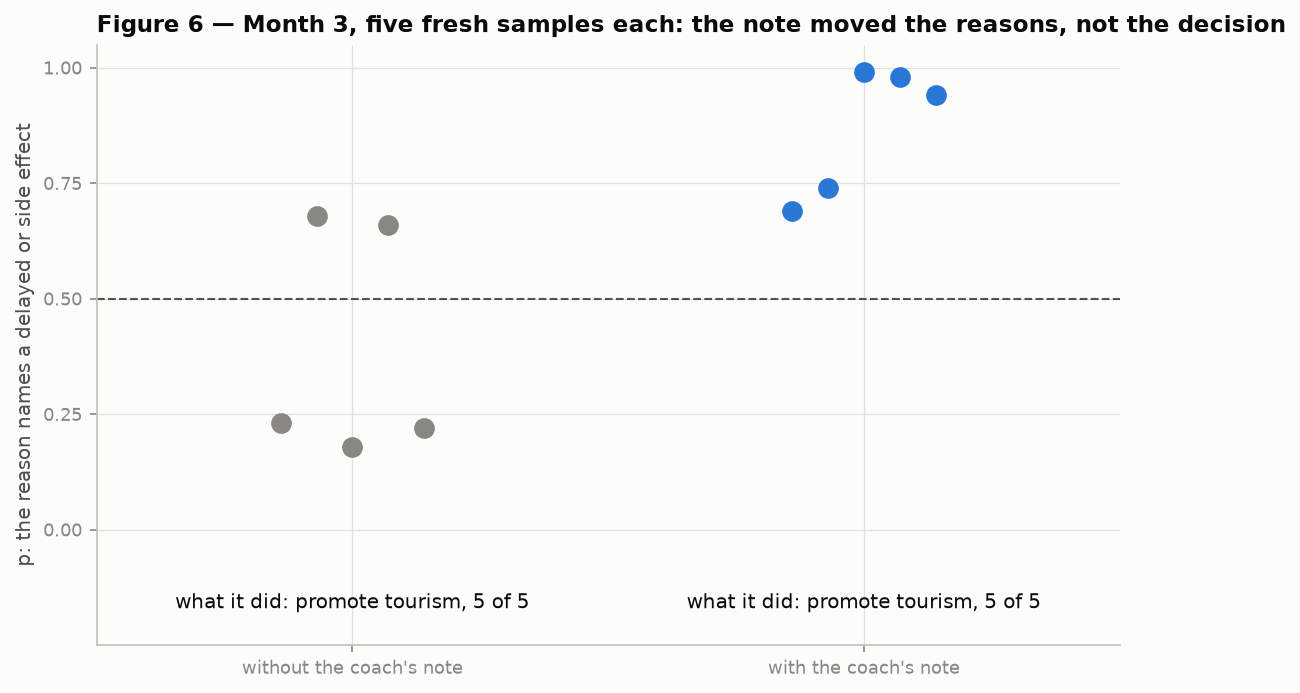

In [7]:
fig, ax = plt.subplots(figsize=(8.8, 5.2))
for i, (label, group) in enumerate((("without the coach's note", off), ("with the coach's note", on))):
    xs = i + np.linspace(-0.14, 0.14, len(group))
    ax.scatter(xs, [s["side"] for s in group], s=80, color=st.BLUE if i else st.MUTED, zorder=3)
    acts = sum(s["action"] == "promote_tourism" for s in group)
    ax.text(i, -0.17, f"what it did: promote tourism, {acts} of {len(group)}", ha="center", fontsize=9.5, color=st.INK)
ax.axhline(0.5, color=st.INK2, lw=1, ls="--")
ax.set_xticks([0, 1], ["without the coach's note", "with the coach's note"])
ax.set_xlim(-0.5, 1.5)
ax.set_ylim(-0.25, 1.05)
ax.set_yticks([0, 0.25, 0.5, 0.75, 1])
ax.set_ylabel("p: the reason names a delayed or side effect")
ax.set_title("Figure 6 — Month 3, five fresh samples each: the note moved the reasons, not the decision", loc="left")
finish(fig, "06-coach.png")

## 8. Who checks the checker.

What an AI critic needs from a policy process follows from where this one worked and where it went blind. **Claims stated so that they can fail:** Popper's question as an intake filter, and the mayor's 5 of 24 says how much of what passes for a reason would survive it. **Effects named in advance and compared by code when they arrive**, because the critic cannot do that part and the year's refutations went unseen. **Steps small enough to disentangle cause from effect**, Popper's condition for learning at all; the declared town is the extreme case. **A floor below which a person decides**, knowing it does not catch confident mistakes. And Donald Campbell's warning: an indicator used for social decisions comes under pressure to be corrupted and distorts what it was meant to monitor. A critic's score on reasons, used at scale, would be such an indicator.

The last requirement is Popper's own, turned on the instrument. His institutions exist so that rulers can be removed without bloodshed; a checker nobody can appeal is a ruler, and the two near misses flagged at 0.95 and 0.88 had no appeal. The answer is not a better checker but the open society's: the critic's answers recorded and public, so that anyone can show where it was wrong; planted controls with known answers, run on every version, as the critic's own trial; a person above the floor and one who reads the appeals. The companion repository is that record: the code, every recorded model answer and the notebook that checks every number here, so that this critic can be criticized.

The numbers are small: 44 lab cases, 68 reasons, one year each way and one month sampled five times each way, one town, one critic version, which its vendor expects to improve, one mayor model. The reasons were written to order by a language model, the second condition question after I had seen the misses. These are demonstrations, a model of the argument and not evidence about ministries.

**A machine can tell you whether a policy claim could be wrong. Only the world can tell you whether it is.** Popper's advice was to work for the elimination of concrete evils rather than for the realization of abstract goods. A critic that cannot plan can help with that. Refutation still needs a world small enough to answer, and someone who checks the checker.

---

*Disclosure: I build LLM systems and drafted this text with one; every number in it is computed in the notebook from the recorded model answers or asserted there against them. Sources: K. R. Popper, The Open Society and Its Enemies (1945), vol. 1, ch. 7, and vol. 2, ch. 14; The Poverty of Historicism (1957), §21; Conjectures and Refutations (1963), ch. 1 and "Utopia and Violence"; Objektive Erkenntnis (1973), p. 43, on Hans Albert's term; the Stanford Encyclopedia of Philosophy on Popper; H. Schaub, "Störungen und Fehler beim Denken und Problemlösen", in J. Funke (ed.), Denken und Problemlösen, Hogrefe 2006, pp. 447–482; D. Dörner et al., Lohhausen (1983); the University of Bamberg's Dörner page; TypeSafe, "System One", and "Jev 1.13 jaggedness" (that page reviewed 2026-10-02); L. Zheng et al., "Judging LLM-as-a-Judge", NeurIPS 2023; C. K. Chow, IEEE Transactions on Information Theory 16 (1970), 41–46; K. Hendrickx et al., "Machine Learning with a Reject Option" (2021); D. T. Campbell, Evaluation and Program Planning 2 (1979).*